#### Read Data

In [1]:
import numpy as np # for array operations and for mean absolute relative error
import pandas as pd # for working with DataFrames

Loading the data set

In [2]:
df = pd.read_csv('permcal.csv')
df.head()

,NPHI,PEF,ILD,CAL,DEPTH,LOGK
0,0.1811,5.4285,2.5559,8.5243,3504.0,0.928206
1,0.1754,5.5042,2.9472,8.5243,3504.1,0.655076
2,0.1703,5.5581,3.0497,8.5243,3504.2,0.558527
3,0.1676,5.5803,3.1619,8.5243,3504.3,0.390858
4,0.1680,5.5785,3.1685,8.5243,3504.4,0.299604


In [3]:
df.corr()["LOGK"].sort_values(ascending=False)

LOGK     1.000000
ILD      0.361133
DEPTH    0.224337
CAL     -0.009127
NPHI    -0.263212
PEF     -0.604485
Name: LOGK, dtype: float64

#### 2.1 Preparing the Data for the Model

In [4]:
X = df.drop(['DEPTH','LOGK'], axis=1) # Features
y = df['LOGK']  # Target

In [5]:
from sklearn.model_selection import GridSearchCV, train_test_split, KFold
from sklearn.preprocessing import MinMaxScaler
import time
from sklearn.svm import SVR
from sklearn.model_selection import cross_val_score
from sklearn import metrics
from sklearn.metrics import r2_score
from sklearn.metrics import mean_absolute_percentage_error
from sklearn.inspection import permutation_importance

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=0)

In [7]:
X_train.shape

(5280, 4)

In [8]:
y_train.shape

(5280,)

In [9]:
X_test.shape

(1320, 4)

In [10]:
y_test.shape

(1320,)

We need to make feature scaling (Normalization or Standarization) before feeding the data to artificial neural networks

In [11]:
# Apply MinMaxScaler to the dataset
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [12]:
svr = SVR()

In [13]:
param_grid = { 
    'C': [0.1, 1, 10, 100], 
    'gamma': [1, 0.1, 0.01, 0.001],
    'kernel': ['rbf', 'sigmoid', 'linear']
}

In [14]:
kfold = KFold(n_splits=10, shuffle=True, random_state=0)

In [15]:
start1 = time.time() #start the timer
cv_tml = GridSearchCV(estimator=svr, param_grid=param_grid, cv=kfold, n_jobs=4, verbose=2) #tml-ensemble machine learning
cv_tml.fit(X_train_scaled, y_train)
end1 = time.time() #end the timer

Fitting 10 folds for each of 48 candidates, totalling 480 fits


In [16]:
cv_tml.best_params_

{'C': 100, 'gamma': 1, 'kernel': 'rbf'}

In [17]:
run_time_1=(end1 - start1)
print("Run Time (S): ", run_time_1) #runtime in seconds

Run Time (S):  194.56719136238098


In [18]:
df_grid_search = pd.DataFrame(cv_tml.cv_results_)
df_grid_search = df_grid_search.sort_values("rank_test_score")
df_grid_search.to_csv("cv_results.csv")

In [19]:
svr1=SVR(C=cv_tml.best_params_['C'], gamma=cv_tml.best_params_['gamma'], kernel=cv_tml.best_params_['kernel'])

In [20]:
start2 = time.time() #start the timer
svr1.fit(X_train_scaled, y_train)
end2 = time.time() #end the timer

In [21]:
run_time_2=(end2 - start2)
print("Run Time (S): ", run_time_2) #runtime in seconds

Run Time (S):  1.6981048583984375


In [22]:
toatal_computational_time=run_time_1+run_time_2
print("Total Computational Time (S): ", toatal_computational_time)

Total Computational Time (S):  196.26529622077942


In [23]:
start3 = time.time() #start the timer
y_train_pred = svr1.predict(X_train_scaled)
end3 = time.time() #end the timer
run_time_3=(end3 - start3)
print("Run Time (S): ", run_time_3) #runtime in seconds

Run Time (S):  1.6421444416046143


In [24]:
start4 = time.time() #start the timer
y_test_pred = svr1.predict(X_test_scaled)
end4 = time.time() #end the timer
run_time_4=(end4 - start4)
print("Run Time (S): ", run_time_4) #runtime in seconds

Run Time (S):  0.40116333961486816


##### Performance Evaluation

##### Learning Curve

In [25]:
from sklearn.model_selection import learning_curve
from sklearn.metrics import make_scorer
import matplotlib.pyplot as plt
import seaborn as sns

In [26]:
# Define R^2 scorer
r2_scorer = make_scorer(r2_score)

In [27]:
# Plot learning curves
train_sizes, train_scores, val_scores = learning_curve(cv_tml.best_estimator_, X_train_scaled, y_train,  
                                                       train_sizes=np.linspace(0.1, 1.0, 10), cv=kfold, scoring=r2_scorer, 
                                                       n_jobs=4, shuffle=True, random_state=0)

In [28]:
train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
val_mean = np.mean(val_scores, axis=1)
val_std = np.std(val_scores, axis=1)

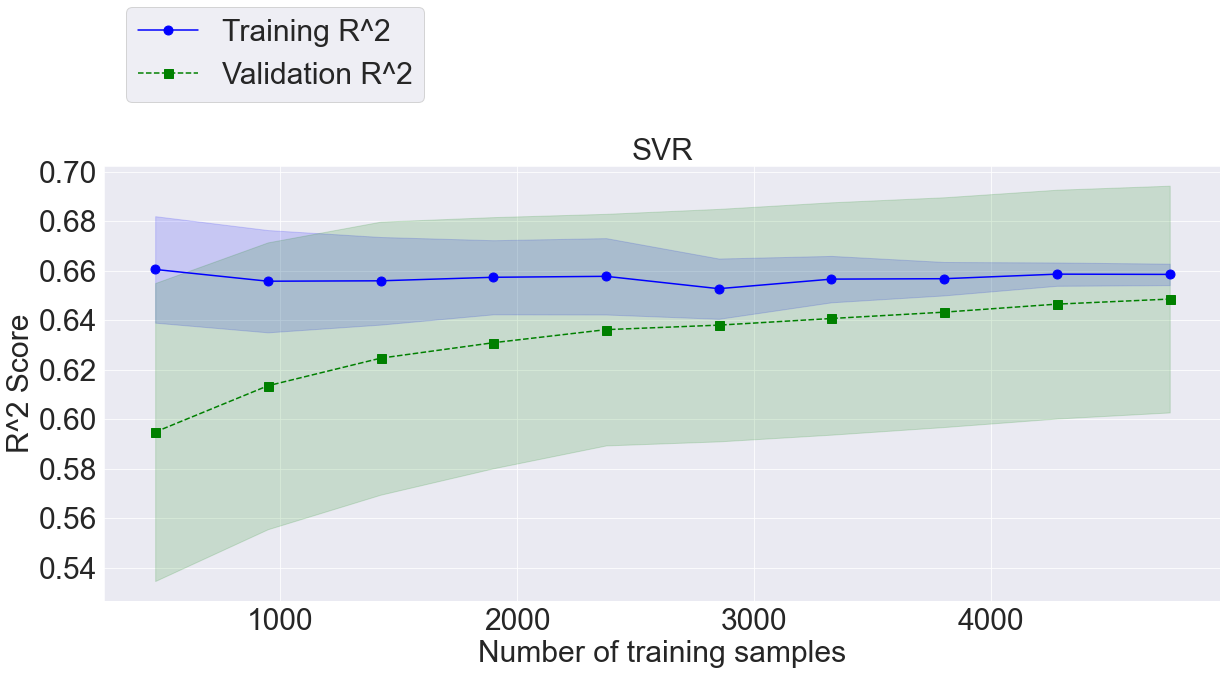

In [29]:
plt.figure(figsize=(20, 8))
sns.set_style("darkgrid")
plt.plot(train_sizes, train_mean, color='blue', marker='o', markersize=9, label='Training R^2')
plt.fill_between(train_sizes, train_mean + train_std, train_mean - train_std, alpha=0.15, color='blue')
plt.plot(train_sizes, val_mean, color='green', linestyle='--', marker='s', markersize=9, label='Validation R^2')
plt.fill_between(train_sizes, val_mean + val_std, val_mean - val_std, alpha=0.15, color='green')
plt.xlabel('Number of training samples', fontsize=30)
plt.ylabel('R^2 Score', fontsize=30)
plt.yticks(fontsize=30)
plt.xticks(fontsize=30)
plt.legend(bbox_to_anchor=(0.3, 1.4), loc='upper right', fontsize=30)
plt.title('SVR', fontsize=30)
plt.show()

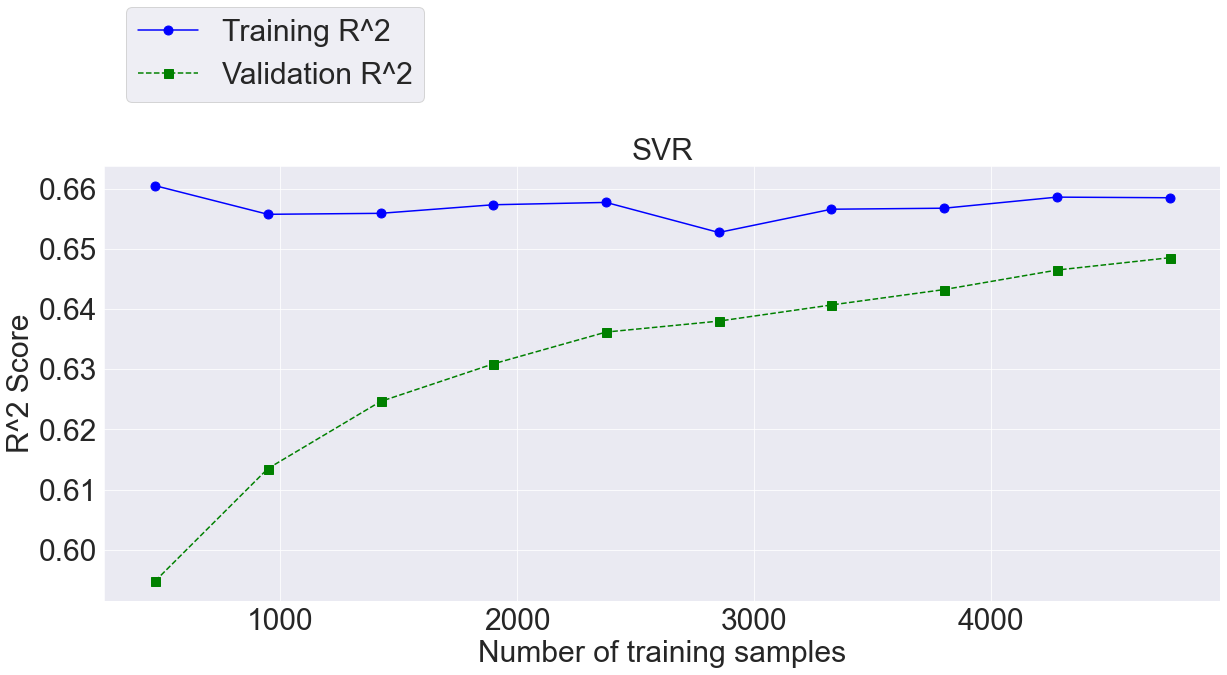

In [30]:
plt.figure(figsize=(20, 8))
sns.set_style("darkgrid")
plt.plot(train_sizes, train_mean, color='blue', marker='o', markersize=9, label='Training R^2')
plt.plot(train_sizes, val_mean, color='green', linestyle='--', marker='s', markersize=9, label='Validation R^2')
plt.xlabel('Number of training samples', fontsize=30)
plt.ylabel('R^2 Score', fontsize=30)
plt.yticks(fontsize=30)
plt.xticks(fontsize=30)
plt.legend(bbox_to_anchor=(0.3, 1.4), loc='upper right', fontsize=30)
plt.title('SVR', fontsize=30)
plt.show()

##### Train model

In [31]:
r2trn = r2_score(y_train, y_train_pred)
print("R2 of the Train Model =", r2trn)

R2 of the Train Model = 0.6595599549634659


In [32]:
msetrn = metrics.mean_squared_error(y_train, y_train_pred)
print("Mean Square Error of Train Model =", msetrn)

Mean Square Error of Train Model = 0.45823678920030214


In [33]:
rmsetrn = msetrn**0.5
print("RMSE of the Train Model =", rmsetrn)

RMSE of the Train Model = 0.6769318940634295


In [34]:
maetrn = metrics.mean_absolute_error(y_train, y_train_pred)
print("Mean Absolute Error of Train Model =", maetrn)

Mean Absolute Error of Train Model = 0.48245546929033994


In [35]:
mapetrn = mean_absolute_percentage_error(y_train, y_train_pred)
print("Mean Absolute Percentage Error of Train Model =", mapetrn)

Mean Absolute Percentage Error of Train Model = 0.8983227355677057


##### Test Model

In [36]:
r2tst = r2_score(y_test, y_test_pred)
print("R2 of the Test Model =", r2tst)

R2 of the Test Model = 0.667075851966278


In [37]:
msetst = metrics.mean_squared_error(y_test, y_test_pred)
print("Mean Square Error of Test Model =", msetst)

Mean Square Error of Test Model = 0.4545672116061018


In [38]:
rmsetst = msetst**0.5
print("RMSE of the Test Model =", rmsetst)

RMSE of the Test Model = 0.6742159977381891


In [39]:
maetst = metrics.mean_absolute_error(y_test, y_test_pred)
print("Mean Absolute Error of Test Model =", maetst)

Mean Absolute Error of Test Model = 0.48525925877926834


In [40]:
mapetst = mean_absolute_percentage_error(y_test, y_test_pred)
print("Mean Absolute Percentage Error of Test Model =", mapetst)

Mean Absolute Percentage Error of Test Model = 6.997123593601175


##### Plots

In [41]:
import seaborn as sns
import matplotlib.pyplot as plt

In [42]:
theta = np.polyfit(y_test, y_test_pred, 1)
print(f'The parameters of the line: {theta}')
y_line = theta[1] + theta[0] * y_test #best fit line

The parameters of the line: [0.6608617  0.55882248]


Text(0.5, 1.0, 'SVR - Training Model')

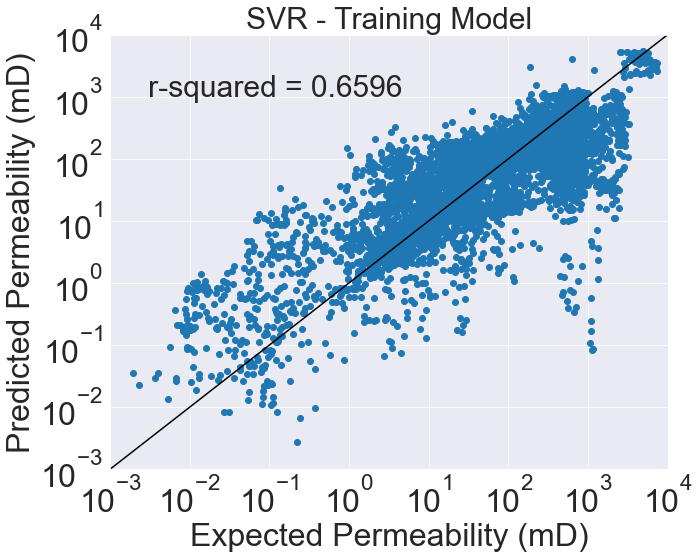

In [43]:
fig = plt.figure(figsize=(10, 8))
sns.set_style("darkgrid")
plt.scatter(10**y_train, 10**y_train_pred)
plt.xlabel('Expected Permeability (mD)', fontsize=32)
plt.ylabel('Predicted Permeability (mD)', fontsize=32)
plt.yticks(fontsize=32)
plt.xticks(fontsize=32)
plt.yscale('log')
plt.xscale('log')
plt.xlim(0.001, 10000)
plt.ylim(0.001, 10000)
plt.plot([0.001, 10000], [0.001, 10000], 'black')
plt.annotate("r-squared = {:.4f}".format(r2_score(y_train, y_train_pred)), (0.003, 1000), fontsize=30)
plt.title('SVR - Training Model', fontsize=30)

Text(0.5, 1.0, 'SVR - Blind Test Model')

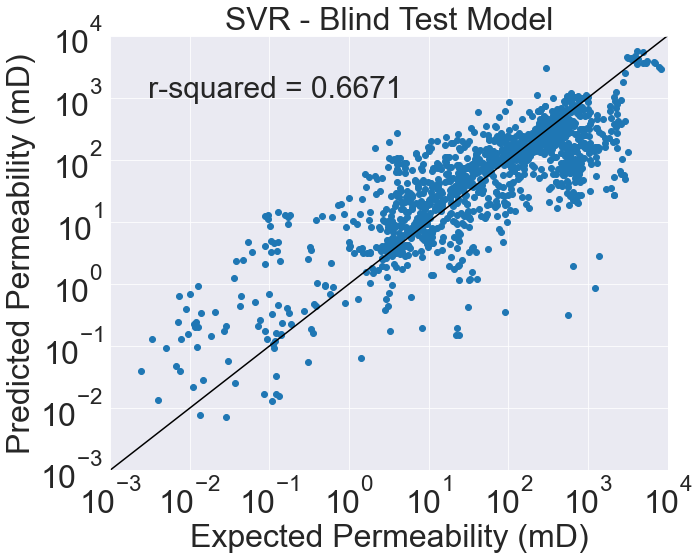

In [44]:
fig = plt.figure(figsize=(10, 8))
sns.set_style("darkgrid")
plt.scatter(10**y_test, 10**y_test_pred)
plt.xlabel('Expected Permeability (mD)', fontsize=32)
plt.ylabel('Predicted Permeability (mD)', fontsize=32)
plt.yticks(fontsize=32)
plt.xticks(fontsize=32)
plt.yscale('log')
plt.xscale('log')
plt.xlim(0.001, 10000)
plt.ylim(0.001, 10000)
plt.plot([0.001, 10000], [0.001, 10000], 'black')
plt.annotate("r-squared = {:.4f}".format(r2_score(y_test, y_test_pred)), (0.003, 1000), fontsize=30)
plt.title('SVR - Blind Test Model', fontsize=32)

##### Feature Importance

Feature Importace Scores of the Train Model:
1    0.576645
2    0.416315
3    0.294345
0    0.161770
Name: value, dtype: float64


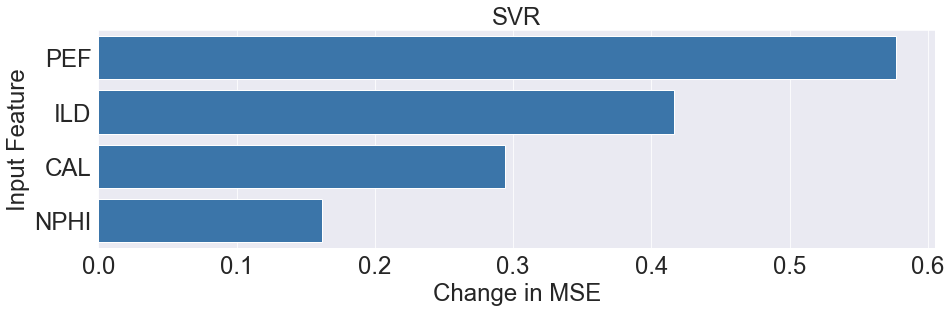

In [45]:
#Train Model

premu_svr_train = permutation_importance(svr1, X_train_scaled, y_train, random_state=0)

# uncomment if you would like to use test data
results_train = [premu_svr_train]

# change name of the models as neccesary
names = ['SVR']

# number of columns in the dataset
n_cols = len(df.columns)

# extract data and names from permutation results
graph_data = {}
for result, name in zip(results_train, names):
    graph_data[name] = result['importances_mean']

# make final dataframe
graph_data = pd.DataFrame.from_dict(graph_data, orient='index', columns=X.columns)
graph_data.reset_index(inplace=True, drop=False)
graph_data.rename(columns={'index': 'model_name'}, inplace=True)
graph_data = graph_data.melt(id_vars='model_name')

#sorting x-axis values
sorted_idx = result.importances_mean.argsort()
sorted_idx_des = sorted_idx[::-1]

# create visual
plt.figure(figsize=[15,4])
sns.barplot(x=graph_data['value'], y=graph_data['variable'][sorted_idx_des], color='#2976bb')
plt.title('SVR', fontsize=24)
plt.xlabel('Change in MSE', fontsize=24)
plt.ylabel('Input Feature',fontsize=24)
plt.yticks(fontsize=24)
plt.xticks(fontsize=24)

print("Feature Importace Scores of the Train Model:")
print(graph_data['value'][sorted_idx_des])

Feature Importace Scoresof the Test Model:
1    0.610579
2    0.406234
3    0.280827
0    0.178366
Name: value, dtype: float64


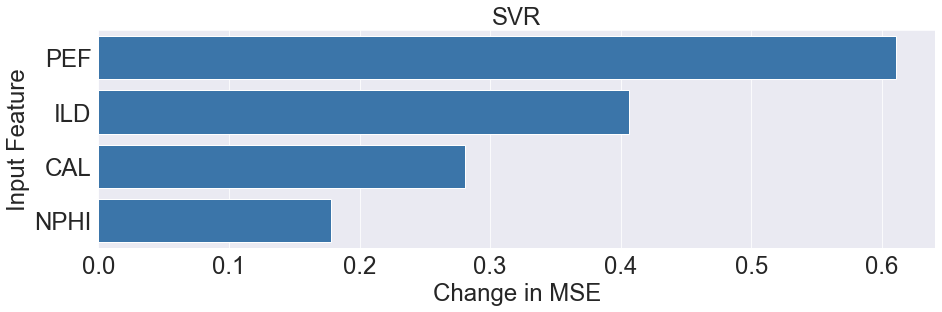

In [46]:
#Test Model

premu_svr_test = permutation_importance(svr1, X_test_scaled, y_test, random_state=0)

# uncomment if you would like to use test data
results_test = [premu_svr_test]

# change name of the models as neccesary
names = ['SVR']

# number of columns in the dataset
n_cols = len(df.columns)

# extract data and names from permutation results
graph_data = {}
for result, name in zip(results_test, names):
    graph_data[name] = result['importances_mean']

# make final dataframe
graph_data = pd.DataFrame.from_dict(graph_data, orient='index', columns=X.columns)
graph_data.reset_index(inplace=True, drop=False)
graph_data.rename(columns={'index': 'model_name'}, inplace=True)
graph_data = graph_data.melt(id_vars='model_name')

#sorting x-axis values
sorted_idx = result.importances_mean.argsort()
sorted_idx_des = sorted_idx[::-1]

# create visual
plt.figure(figsize=[15,4])
sns.barplot(x=graph_data['value'], y=graph_data['variable'][sorted_idx_des], color='#2976bb')
plt.title('SVR', fontsize=24)
plt.xlabel('Change in MSE', fontsize=24)
plt.ylabel('Input Feature',fontsize=24)
plt.yticks(fontsize=24)
plt.xticks(fontsize=24)

print("Feature Importace Scoresof the Test Model:")
print(graph_data['value'][sorted_idx_des])

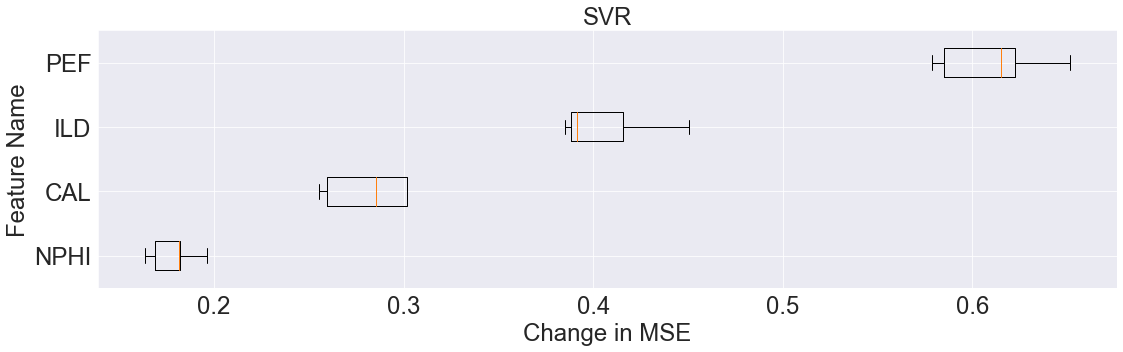

In [47]:
fig = plt.figure(figsize=(30, 5))
sns.set_style("darkgrid")
result = permutation_importance(
    svr1, X_test_scaled, y_test, random_state=0)
sorted_idx = result.importances_mean.argsort()
plt.subplot(1, 2, 2)
plt.boxplot(
    result.importances[sorted_idx].T,
    vert=False,
    labels=np.array(['NPHI', 'PEF', 'ILD', 'CAL'])[sorted_idx]
)
plt.title('SVR', fontsize=24)
plt.xlabel('Change in MSE', fontsize=24)
plt.ylabel('Feature Name', fontsize=24)
plt.yticks(fontsize=24)
plt.xticks(fontsize=24)
fig.tight_layout()
plt.show()

In [48]:
y_train

3158    0.249479
5328    2.732910
5375    2.846956
4970    3.318404
3429    2.597947
          ...   
4931    3.115422
3264    1.086641
1653    0.445539
2607    1.399920
2732   -0.709188
Name: LOGK, Length: 5280, dtype: float64

In [49]:
y_train_index=y_train.index #index of y_train data

In [50]:
y_train_sort=y_train.sort_index(axis = 0) #sorting y_train based on index number

In [51]:
y_train_sort_index=y_train_sort.index

##### Training and Validation Plots - Against Indices

Text(0.5, 1.0, 'SVR - (Index 0 - 500)')

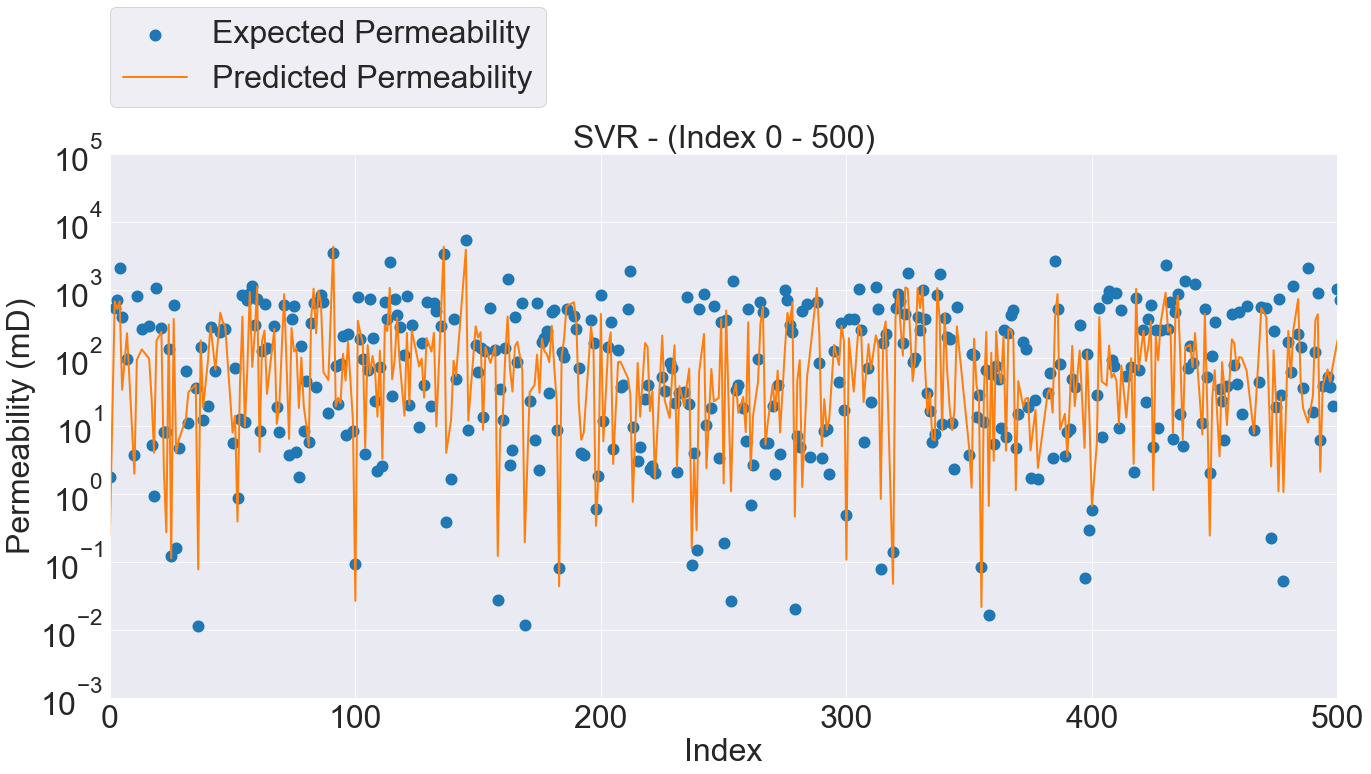

In [52]:
plt.figure(figsize=(22,10))
sns.set_style("darkgrid")
plt.xlabel('Index', fontsize=32)
plt.ylabel('Permeability (mD)', fontsize=32)
plt.yticks(fontsize=32)
plt.xticks(fontsize=32)
plt.scatter(y_train_sort_index, 10**y_train, label = 'Expected Permeability', linewidth=6, color='#1f77b4')
plt.plot(y_train_sort_index, 10**y_train_pred, label = 'Predicted Permeability', linewidth=2, color='#ff7f0e')
plt.yscale('log')
plt.legend(bbox_to_anchor=(0.368, 1.3), loc='upper right', fontsize=32)
plt.ylim(0.001, 100000)
plt.xlim(0, 500)
plt.title('SVR - (Index 0 - 500)', fontsize=32)

In [66]:
y_test

4676    2.764889
578     0.924444
1362    1.930943
5628    2.780292
4045    2.477114
          ...   
2843    1.663215
5220    2.862423
5002    3.137125
5222    2.881811
3055    0.447475
Name: LOGK, Length: 1320, dtype: float64

In [67]:
y_test_index=y_test.index

In [68]:
y_test_sort=y_test.sort_index(axis = 0)

In [69]:
y_test_sort_index=y_test_sort.index

##### Testing/Blind Test Plots - Against Indices

Text(0.5, 1.0, 'SVR - (Index 0 - 1000)')

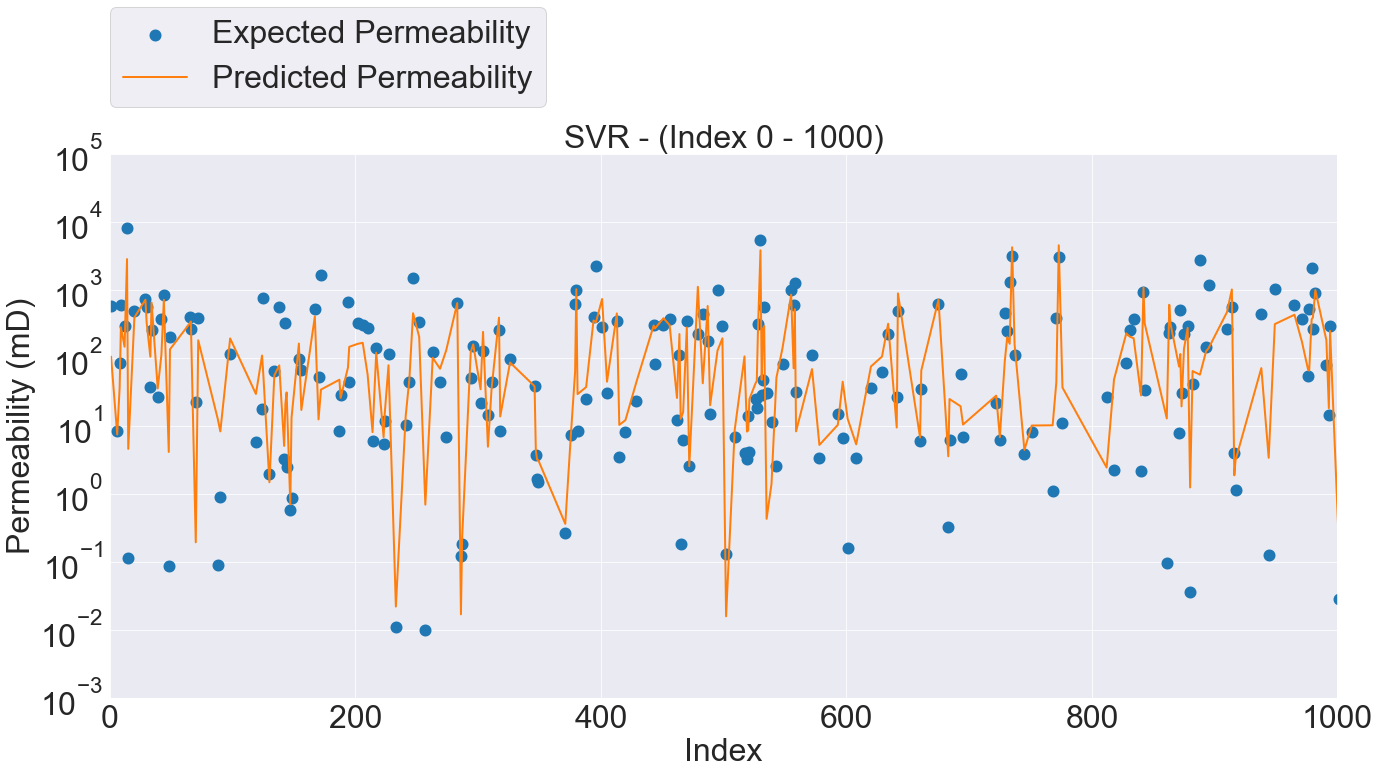

In [70]:
plt.figure(figsize=(22,10))
sns.set_style("darkgrid")
plt.xlabel('Index', fontsize=32)
plt.ylabel('Permeability (mD)', fontsize=32)
plt.yticks(fontsize=32)
plt.xticks(fontsize=32)
plt.scatter(y_test_sort_index, 10**y_test, label = 'Expected Permeability', linewidth=6, color='#1f77b4')
plt.plot(y_test_sort_index, 10**y_test_pred, label = 'Predicted Permeability', linewidth=2, color='#ff7f0e')
plt.yscale('log')
plt.legend(bbox_to_anchor=(0.368, 1.3), loc='upper right', fontsize=32)
plt.ylim(0.001, 100000)
plt.xlim(0, 1000)
plt.title('SVR - (Index 0 - 1000)', fontsize=32)

##### Saving data to Excel Files

###### Training data with depth

In [125]:
df_train=pd.DataFrame(y_train.sort_index(axis=0))

In [126]:
df_train_depth=pd.DataFrame(df['DEPTH'].iloc[y_train.sort_index(axis = 0).index])

In [127]:
df_train_depth_merged=pd.concat([df_train, df_train_depth], axis=1)

In [128]:
df_train_depth_merged.to_excel(excel_writer = "actual_train.xlsx")

###### Predicted training data with depth

In [129]:
df_train_pred=pd.DataFrame(y_train_pred)

In [130]:
index_train_pred=pd.DataFrame(X_train.index)

In [131]:
index_train_pred_merged=pd.concat([index_train_pred, df_train_pred], axis=1)

In [132]:
index_train_pred_merged.columns='Index','Predicted Train'

In [133]:
index_train_pred_merged_sorted=pd.DataFrame(index_train_pred_merged.sort_values(by='Index', ascending=True))

In [134]:
set_index_index_train_pred_merged_sorted=index_train_pred_merged_sorted.set_index('Index')

In [135]:
df_train_pred_depth_merged=pd.concat([set_index_index_train_pred_merged_sorted, df_train_depth], axis=1)

In [136]:
df_train_pred_depth_merged.to_excel(excel_writer = "predicted_train.xlsx")

###### Testing data with depth

In [137]:
df_test=pd.DataFrame(y_test.sort_index(axis=0))

In [138]:
df_test_depth=pd.DataFrame(df['DEPTH'].iloc[y_test.sort_index(axis = 0).index])

In [139]:
df_test_depth_merged=pd.concat([df_test, df_test_depth], axis=1)

In [140]:
df_test_depth_merged.to_excel(excel_writer = "actual_test.xlsx")

###### Predicted testing data with depth

In [141]:
df_test_pred=pd.DataFrame(y_test_pred)

In [142]:
index_test_pred=pd.DataFrame(X_test.index)

In [143]:
index_test_pred_merged=pd.concat([index_test_pred, df_test_pred], axis=1)

In [144]:
index_test_pred_merged.columns='Index','Predicted Test'

In [145]:
index_test_pred_merged_sorted=pd.DataFrame(index_test_pred_merged.sort_values(by='Index', ascending=True))

In [146]:
set_index_index_test_pred_merged_sorted=index_test_pred_merged_sorted.set_index('Index')

In [147]:
df_test_pred_depth_merged=pd.concat([set_index_index_test_pred_merged_sorted, df_test_depth], axis=1)

In [148]:
df_test_pred_depth_merged.to_excel(excel_writer = "predicted_test.xlsx")